# Pair 2: NeRF vs 3D Gaussian Splatting for 360 degree product views

**Brief reference:** Section 2.1 (AI generation models in 3D, perception and computer vision), Section 2.2, Section 3.1 to 3.3. Lecture link: 3D generation Lecture A (volume rendering, NeRF, Instant-NGP style hash grids, 3D Gaussian Splatting, rasterisation).

**Scenario.** A home-decor retailer wants an interactive 360 degree view of each product built from a set of photographs. Two reconstruction methods are compared on the same captures, trained inside the same framework (nerfstudio 1.1.5) so that data loading, camera handling and metrics are identical:

| | System A | System B |
|---|---|---|
| Method | nerfacto (NeRF) | splatfacto (3D Gaussian Splatting) |
| Representation | Neural radiance field: hash-grid encoding plus a small MLP, proposal-network sampling | Millions of 3D Gaussians (position, scale, rotation, opacity, colour) |
| Rendering | Volume rendering along rays | Tile-based rasterisation of projected 2D Gaussians |
| Implementation here | Pure-PyTorch hash grid (tiny-cuda-nn and nerfacc kernels could not be built on this machine), so it is slower than a CUDA build | gsplat 1.5.3 CUDA kernels compiled for the RTX 5070 |

**Scenes**
- **chair (optional, not part of the reported run):** NeRF-synthetic Blender scene (Mildenhall et al., 2020). Pure-PyTorch nerfacto at 800 x 800 px exceeded the 8 GB GPU during the periodic evaluation render and was dropped; the second scene is my own phone video of a chair, processed with COLMAP.
- **chair_video:** my own phone video of an office chair (two circles around it, 42 s and 34 s, 1280 x 720, 30 fps). Frames were taken at 2.5 per second, camera poses were estimated with COLMAP in one joint model (182 of 182 frames registered, 16,914 points, mean reprojection error 0.58 px; `src/prepare_chair_video.py`). The low circle (101 frames) is used for training and the higher circle (81 frames, a different camera height and path) for testing, so the test views are genuinely new viewpoints. Images were used at 480 x 270.
- **poster:** a real handheld capture from the nerfstudio sample data (HuggingFace `nerfstudioteam/datasets`; the dataset is called `poster`, the capture shows a folding chair in a room). 100 frames at quarter resolution (270 x 480 px) with COLMAP poses. The copy online holds 100 of the 226 frames listed in its `transforms.json`, so a trimmed file listing the existing frames is used.

**Evaluation design**
- Same scenes, same framework, one training run per method and scene. The main comparison uses nerfacto at 2,500 iterations and splatfacto at 15,000 iterations (nerfacto's default is about 30,000, so it is trained to a fraction of its normal budget; wall time is 583 s against 222 s, not equal). Section 4b adds a quality against training-effort curve with more nerfacto iterations and fewer splatfacto iterations so that the effect of the budget can be read directly.
- **Quality:** PSNR, SSIM and LPIPS (nerfstudio's metric code) on held-out views.
- **Speed:** training time, rendering FPS on the GPU.
- **Resources:** peak GPU memory, model size on disk, number of Gaussians, GPU energy.
- GPU power is sampled with `nvidia-smi`; an electricity price is an explicit assumption.
- A first, untimed warm-up run compiles the CUDA kernels so that compilation does not count as training time.

In [1]:
import os, sys, io, json, time, re, random, pathlib, platform, subprocess, threading, importlib.metadata as im, warnings, shutil
import numpy as np, pandas as pd
from PIL import Image
warnings.filterwarnings("ignore")

QUICK = os.environ.get("P2_QUICK", "0") == "1"
HERE = pathlib.Path.cwd()
RESULTS = pathlib.Path(os.environ.get("P2_RESULTS", HERE.parent / "results")); RESULTS.mkdir(parents=True, exist_ok=True)
OUT = RESULTS / "ns_runs"; OUT.mkdir(exist_ok=True)
PY = r"C:\envs\p2_nerf\Scripts\python.exe"             # venv with nerfstudio 1.1.5, gsplat 1.5.3, nerfacc 0.5.2
SCENES = {
    "chair": {"data": r"C:\data\nerf_synth\chair", "parser": ["blender-data"], "eval_mode": "val"},
    "chair_video": {"data": os.environ.get("P2_CHAIR_VIDEO", r"C:\data\chair_video\ns\transforms.json"), "parser": ["nerfstudio-data", "--downscale-factor", "2", "--eval-mode", "filename"], "eval_mode": "test"},
    "poster": {"data": r"C:\data\ns_sample\poster\transforms_subset.json", "parser": ["nerfstudio-data", "--downscale-factor", "4"], "eval_mode": "test"},
}
WANTED = os.environ.get("P2_SCENES", "poster,chair_video").split(",")  # the chair scene stalled nerfacto on this laptop (see work log); add it back with P2_SCENES=poster,chair_video,chair
SCENES = {k: v for k, v in SCENES.items() if k in WANTED}
# iteration budgets chosen after timing tests: nerfacto 2,500 iterations (about 580 s) and splatfacto 15,000 iterations (about 200 to 220 s), so the wall-clock times are not equal; the budget curve shows the effect of the budget
TRAIN_SEED = os.environ.get("P2_SEED")      # replicate runs: nerfstudio machine seed (default 42 when unset)
ITERS = {"nerfacto": int(os.environ.get("P2_NERF_ITERS", 2500)), "splatfacto": int(os.environ.get("P2_SPLAT_ITERS", 7000))}
EVAL_VIEWS = 20                                          # views rendered per scene for the metrics (evenly spaced)
if QUICK:
    SCENES = {"poster": SCENES["poster"]}; ITERS = {"nerfacto": 60, "splatfacto": 100}; EVAL_VIEWS = 3
ELECTRICITY_AUD_PER_KWH = 0.30                           # ASSUMPTION for the cost estimate, not measured
print("quick:", QUICK, "| scenes:", list(SCENES), "| iterations:", ITERS, "| results:", RESULTS)

quick: False | scenes: ['chair_video', 'poster'] | iterations: {'nerfacto': 2500, 'splatfacto': 15000} | results: C:\prsnl data\vscode\adv AI\a1\COMP8410_A1\pairs\p2_3d_reconstruction\results\replicate_seed1


## 1. Environment record and build wrapper
Training and evaluation run in child processes inside the Visual Studio developer shell (needed to compile the gsplat CUDA extension). The wrapper below is written once and reused.

In [2]:
def smi(query):
    try: return subprocess.check_output(["nvidia-smi", f"--query-gpu={query}", "--format=csv,noheader,nounits"], text=True).strip()
    except Exception as e: return f"unavailable ({e})"

NINJA_DIR = os.path.dirname(shutil.which("ninja") or r"C:\Users\verma\AppData\Local\Microsoft\WinGet\Packages\Ninja-build.Ninja_Microsoft.Winget.Source_8wekyb3d8bbwe\ninja.exe")
WRAPPER = RESULTS / "_build_env.bat"
WRAPPER.write_text("\r\n".join([
    "@echo off",
    r'call "C:\Program Files (x86)\Microsoft Visual Studio\2022\BuildTools\VC\Auxiliary\Build\vcvars64.bat" >nul',
    r'set "CUDA_HOME=C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.8"',
    r'set "CUDA_PATH=%CUDA_HOME%"',
    rf'set "PATH=%CUDA_HOME%\bin;C:\Program Files\CMake\bin;{NINJA_DIR};%PATH%"',
    "set TORCH_CUDA_ARCH_LIST=12.0", "set DISTUTILS_USE_SDK=1",
    'set "NVCC_APPEND_FLAGS=-DWIN32_LEAN_AND_MEAN -DNOMINMAX"', "set PYTHONIOENCODING=utf-8", "%*", ""]))

ver = subprocess.check_output([PY, "-c", "import importlib.metadata as m;print({k: m.version(k) for k in ('nerfstudio','gsplat','nerfacc','torch','numpy')})"], text=True).strip().splitlines()[-1]
env_record = {"date": time.strftime("%Y-%m-%d %H:%M:%S"), "python": platform.python_version(), "os": platform.platform(), "venv_packages": ver,
              "gpu": smi("name"), "gpu_memory_total_mib": smi("memory.total"), "driver": smi("driver_version"),
              "scenes": {k: v["data"] for k, v in SCENES.items()}, "iterations": ITERS, "eval_views": EVAL_VIEWS, "quick": QUICK}
(RESULTS / "environment.json").write_text(json.dumps(env_record, indent=2)); print(json.dumps(env_record, indent=2))

{
  "date": "2026-10-27 19:21:53",
  "python": "3.11.9",
  "os": "Windows-10-10.0.26300-SP0",
  "venv_packages": "{'nerfstudio': '1.1.5', 'gsplat': '1.5.3', 'nerfacc': '0.5.2', 'torch': '2.11.0+cu128', 'numpy': '1.26.4'}",
  "gpu": "NVIDIA GeForce RTX 5070 Laptop GPU",
  "gpu_memory_total_mib": "8151",
  "driver": "610.88",
  "scenes": {
    "chair_video": "C:\\data\\chair_video\\ns\\transforms.json",
    "poster": "C:\\data\\ns_sample\\poster\\transforms_subset.json"
  },
  "iterations": {
    "nerfacto": 2500,
    "splatfacto": 15000
  },
  "eval_views": 20,
  "quick": false
}


## 2. Training
Each run is a child process (`ns-train`). Wall time, the trainer's own mean time per iteration, and GPU power are recorded. An untimed warm-up run of 10 iterations per method compiles the CUDA kernels first. Finished runs (a saved checkpoint) are skipped.

In [3]:
class GpuSampler:
    def __init__(self): self.vals, self._run = [], False
    def _loop(self):
        while self._run:
            try:
                p, u, m = smi("power.draw,utilization.gpu,memory.used").split(", "); self.vals.append((float(p), float(u), float(m)))
            except Exception: pass
            time.sleep(1.0)
    def start(self): self._run = True; self.t0 = time.time(); self.th = threading.Thread(target=self._loop, daemon=True); self.th.start()
    def stop(self):
        self._run = False; self.th.join(timeout=3); dur = time.time() - self.t0; a = np.array(self.vals) if self.vals else np.zeros((1, 3))
        return {"duration_s": round(dur, 1), "mean_power_w": round(float(a[:, 0].mean()), 1), "mean_util_pct": round(float(a[:, 1].mean()), 1),
                "peak_mem_mib": float(a[:, 2].max()), "energy_wh": round(float(a[:, 0].mean()) * dur / 3600, 3)}

MEM_CAP_GB = 16                                          # hard commit limit for each nerfstudio job (all its processes); the laptop has 32 GB RAM
CAPPED = RESULTS / "_capped_run.py"
CAPPED.write_text(r"""
import sys, subprocess, ctypes
from ctypes import wintypes
cap_gb, cmd = float(sys.argv[1]), sys.argv[2:]
class IO(ctypes.Structure): _fields_ = [(n, ctypes.c_ulonglong) for n in ("r1", "r2", "r3", "r4", "r5", "r6")]
class BASIC(ctypes.Structure): _fields_ = [("PerProcessUserTimeLimit", ctypes.c_longlong), ("PerJobUserTimeLimit", ctypes.c_longlong), ("LimitFlags", wintypes.DWORD),
    ("MinimumWorkingSetSize", ctypes.c_size_t), ("MaximumWorkingSetSize", ctypes.c_size_t), ("ActiveProcessLimit", wintypes.DWORD), ("Affinity", ctypes.c_size_t),
    ("PriorityClass", wintypes.DWORD), ("SchedulingClass", wintypes.DWORD)]
class EXT(ctypes.Structure): _fields_ = [("Basic", BASIC), ("Io", IO), ("ProcessMemoryLimit", ctypes.c_size_t), ("JobMemoryLimit", ctypes.c_size_t),
    ("PeakProcessMemoryUsed", ctypes.c_size_t), ("PeakJobMemoryUsed", ctypes.c_size_t)]
k = ctypes.WinDLL("kernel32", use_last_error=True)
k.CreateJobObjectW.restype = wintypes.HANDLE
k.GetCurrentProcess.restype = wintypes.HANDLE
k.SetInformationJobObject.argtypes = [wintypes.HANDLE, ctypes.c_int, ctypes.c_void_p, wintypes.DWORD]
k.AssignProcessToJobObject.argtypes = [wintypes.HANDLE, wintypes.HANDLE]
job = k.CreateJobObjectW(None, None); info = EXT()
info.Basic.LimitFlags = 0x200 | 0x2000          # job memory limit, kill everything when the launcher exits
info.JobMemoryLimit = int(cap_gb * 2**30)
assert k.SetInformationJobObject(job, 9, ctypes.byref(info), ctypes.sizeof(info)), ctypes.get_last_error()
assert k.AssignProcessToJobObject(job, k.GetCurrentProcess()), ctypes.get_last_error()
sys.exit(subprocess.call(cmd))
""")

TRAIN_PLAIN = RESULTS / "_train_plain.py"
TRAIN_PLAIN.write_text(r"""
# nerfacto training with the plain data manager: the default parallel one stalled on this Windows laptop after a few hundred iterations
import os, sys, copy, pathlib, torch
torch.cuda.set_per_process_memory_fraction(0.92)
from nerfstudio.configs.method_configs import all_methods
from nerfstudio.data.datamanagers.base_datamanager import VanillaDataManagerConfig
from nerfstudio.data.dataparsers.blender_dataparser import BlenderDataParserConfig
from nerfstudio.data.dataparsers.nerfstudio_dataparser import NerfstudioDataParserConfig
from nerfstudio.scripts.train import main
if __name__ == "__main__":
    data, kind, iters, outdir, exp, ts = sys.argv[1], sys.argv[2], int(sys.argv[3]), sys.argv[4], sys.argv[5], sys.argv[6]
    ds, em = (int(sys.argv[7]), sys.argv[8]) if len(sys.argv) > 8 else (4, "fraction")
    cfg = copy.deepcopy(all_methods["nerfacto"]); old = cfg.pipeline.datamanager
    parser = BlenderDataParserConfig() if kind == "blender" else NerfstudioDataParserConfig(downscale_factor=ds, eval_mode=em)
    cfg.pipeline.datamanager = VanillaDataManagerConfig(dataparser=parser, train_num_rays_per_batch=old.train_num_rays_per_batch,
                                                        eval_num_rays_per_batch=old.eval_num_rays_per_batch, camera_optimizer=old.camera_optimizer)
    cfg.data = pathlib.Path(data)
    cfg.pipeline.model.implementation = "torch"
    cfg.pipeline.model.eval_num_rays_per_chunk = 4096       # the default (32768 rays per chunk) needs more than the 8 GB card holds when it renders the periodic eval image
    cfg.steps_per_eval_image = 10**9; cfg.steps_per_eval_batch = 10**9   # no in-training evaluation, the models are scored afterwards on fixed views
    cfg.machine.seed = int(os.environ["P2_SEED"]) if os.environ.get("P2_SEED") else cfg.machine.seed; cfg.max_num_iterations = iters; cfg.steps_per_save = iters; cfg.vis = "tensorboard"; cfg.viewer.quit_on_train_completion = True
    cfg.output_dir = pathlib.Path(outdir); cfg.experiment_name = exp; cfg.timestamp = ts
    main(cfg)
""")

def sh(args, log=None):
    cmdline = " ".join(f'"{a}"' if (" " in str(a) or chr(92) in str(a)) else str(a) for a in args)
    p = subprocess.Popen(f'cmd /c ""{WRAPPER}" "{sys.executable}" "{CAPPED}" {MEM_CAP_GB} {cmdline}"', shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
    lines = []
    for line in p.stdout:
        lines.append(line.rstrip())
        if log: log.write(line); log.flush()
    p.wait(); return p.returncode, chr(10).join(lines)

def train_cmd(method, scene, iters, name, exp):
    S = SCENES[scene]
    if method == "nerfacto":
        pa = S["parser"]; ds = pa[pa.index("--downscale-factor") + 1] if "--downscale-factor" in pa else "4"; em = pa[pa.index("--eval-mode") + 1] if "--eval-mode" in pa else "fraction"
        return [PY, str(TRAIN_PLAIN), S["data"], "blender" if pa[0] == "blender-data" else "nerfstudio", str(iters), str(OUT), exp, name, ds, em]
    return [PY, "-m", "nerfstudio.scripts.train", method, "--data", S["data"], "--output-dir", str(OUT), "--experiment-name", exp, "--timestamp", name,
            "--max-num-iterations", str(iters), "--steps-per-save", str(iters), "--vis", "tensorboard", "--viewer.quit-on-train-completion", "True",
            "--steps-per-eval-batch", "1000000000", "--steps-per-eval-image", "1000000000", "--steps-per-eval-all-images", "1000000000"] + (["--machine.seed", TRAIN_SEED] if TRAIN_SEED else []) + S["parser"]   # in-training eval divides by a zero timer reading on Windows

TRAIN_LOG = RESULTS / "train_log.jsonl"
def config_path(scene, method): return OUT / f"{scene}_{method}" / method / "run" / "config.yml"
def trained(scene, method): return (OUT / f"{scene}_{method}" / method / "run" / "nerfstudio_models").glob("step-*.ckpt")

for method in ITERS:                                               # untimed warm-up: compiles kernels, checks the pipeline
    scene = next(iter(SCENES)); rc, _ = sh(train_cmd(method, scene, 10, "warmup", f"warmup_{method}"))
    print("warm-up", method, "exit", rc)

for scene in SCENES:
    for method, iters in ITERS.items():
        if list(trained(scene, method)): print(scene, method, "already trained"); continue
        sampler = GpuSampler(); sampler.start(); t0 = time.time()
        with (RESULTS / f"train_{scene}_{method}.log").open("w", encoding="utf-8") as lg: rc, text = sh(train_cmd(method, scene, iters, "run", f"{scene}_{method}"), lg)
        wall = time.time() - t0; en = sampler.stop()
        m = re.search(r"Trainer\.train_iteration:\s*([0-9.]+)", text); per_it = float(m.group(1)) if m else None
        rec = {"scene": scene, "method": method, "iterations": iters, "exit": rc, "wall_s": round(wall, 1), "sec_per_iter": per_it,
               "train_compute_s": round(per_it * iters, 1) if per_it else None, **en}
        with TRAIN_LOG.open("a") as f: f.write(json.dumps(rec) + "\n")
        print(rec)
        assert rc == 0, f"training failed for {scene} {method}: see train_{scene}_{method}.log"

warm-up nerfacto exit 0


warm-up splatfacto exit 0
chair_video nerfacto already trained
chair_video splatfacto already trained
poster nerfacto already trained
poster splatfacto already trained


## 3. Evaluation on held-out views
A worker script (written below) loads each trained model with nerfstudio's `eval_setup`, renders up to 10 held-out views of the evaluation split (all of them when fewer exist), and records nerfstudio's image metrics (PSNR, SSIM, LPIPS), render time per view, peak GPU memory, checkpoint size and, for splatfacto, the number of Gaussians. The first rendered views are saved next to the ground truth.

In [4]:
EVAL_WORKER = RESULTS / "_eval_worker.py"
EVAL_WORKER.write_text(r"""
import sys, json, time, pathlib, torch
torch.cuda.set_per_process_memory_fraction(0.92)
_load = torch.load      # nerfstudio checkpoints hold config objects; torch >= 2.6 defaults to weights_only=True and refuses them (own checkpoints, trusted)
torch.load = lambda *a, **k: _load(*a, **{**k, 'weights_only': k.get('weights_only', False)})
from nerfstudio.utils.eval_utils import eval_setup
cfg_path, mode, n_views, out_json, img_dir = pathlib.Path(sys.argv[1]), sys.argv[2], int(sys.argv[3]), pathlib.Path(sys.argv[4]), pathlib.Path(sys.argv[5])
img_dir.mkdir(parents=True, exist_ok=True)
def use_plain_datamanager(config):
    # the parallel data manager spawns worker processes and pickles this whole script (including the loaded model) on Windows, which hangs;
    # evaluation only reads images, so the plain data manager gives the same views
    dm = config.pipeline.datamanager
    if type(dm).__name__ == "ParallelDataManagerConfig":
        from nerfstudio.data.datamanagers.base_datamanager import VanillaDataManagerConfig
        config.pipeline.datamanager = VanillaDataManagerConfig(data=dm.data, dataparser=dm.dataparser, train_num_rays_per_batch=dm.train_num_rays_per_batch,
                                                                eval_num_rays_per_batch=dm.eval_num_rays_per_batch, camera_optimizer=dm.camera_optimizer)
    elif type(dm).__name__ == "VanillaDataManagerConfig":
        from nerfstudio.data.datamanagers.base_datamanager import VanillaDataManager
        dm._target = VanillaDataManager
    return config
config, pipeline, ckpt, step = eval_setup(cfg_path, eval_num_rays_per_chunk=4096, test_mode=mode, update_config_callback=use_plain_datamanager)
pipeline.eval(); model = pipeline.model
dl = pipeline.datamanager.fixed_indices_eval_dataloader
has_loader = hasattr(dl, 'input_dataset')            # ray-based methods give a dataloader, splatfacto gives a list of (camera, batch)
total = len(dl.input_dataset) if has_loader else len(dl)
idx = sorted(set(round(i * (total - 1) / max(n_views - 1, 1)) for i in range(n_views))) if n_views > 1 else [0]
if has_loader: dl.image_indices = tuple(idx)
loader = dl if has_loader else [dl[i] for i in idx]
torch.cuda.reset_peak_memory_stats()
rows = []
with torch.no_grad():
    for k, (camera, batch) in enumerate(loader):
        torch.cuda.synchronize(); t = time.perf_counter()
        outputs = model.get_outputs_for_camera(camera=camera)
        torch.cuda.synchronize(); dt = time.perf_counter() - t
        metrics, images = model.get_image_metrics_and_images(outputs, batch)
        row = {"view": int(idx[k]), "render_s": dt, "fps": 1.0 / dt, "height": int(camera.height), "width": int(camera.width)}
        row.update({kk: float(v) for kk, v in metrics.items() if kk in ("psnr", "ssim", "lpips")})
        rows.append(row)
        if k < 3:
            import torchvision
            for name, im in images.items():
                torchvision.utils.save_image(im.permute(2, 0, 1).cpu(), str(img_dir / f"view{idx[k]}_{name}.png"))
info = {"checkpoint": str(ckpt), "step": int(step), "ckpt_mb": round(ckpt.stat().st_size / 2**20, 1) if ckpt.is_file() else None,
        "num_gaussians": int(model.means.shape[0]) if hasattr(model, "means") else None,
        "peak_alloc_gb": round(torch.cuda.max_memory_allocated() / 2**30, 2), "rows": rows}
out_json.write_text(json.dumps(info))
print("EVAL DONE", len(rows), "views")
""")

def checkpoint_file(scene, method):
    c = sorted((OUT / f"{scene}_{method}" / method / "run" / "nerfstudio_models").glob("step-*.ckpt")); return c[-1] if c else None

EVAL_JSON = {}
for scene in SCENES:
    for method in ITERS:
        out_json = RESULTS / f"eval_{scene}_{method}.json"
        if not out_json.exists():
            rc, text = sh([PY, str(EVAL_WORKER), str(config_path(scene, method)), SCENES[scene]["eval_mode"], str(EVAL_VIEWS), str(out_json), str(RESULTS / "renders" / f"{scene}_{method}")])
            assert rc == 0 and out_json.exists(), f"evaluation failed for {scene} {method}:\n{text[-1500:]}"
        EVAL_JSON[(scene, method)] = json.loads(out_json.read_text())
        d = EVAL_JSON[(scene, method)]; print(scene, method, "views:", len(d["rows"]), "| mean PSNR %.2f" % np.mean([r["psnr"] for r in d["rows"]]))

chair_video nerfacto views: 20 | mean PSNR 19.62
chair_video splatfacto views: 20 | mean PSNR 24.36
poster nerfacto views: 10 | mean PSNR 20.67
poster splatfacto views: 10 | mean PSNR 32.77


## 4. Results

In [5]:
from scipy import stats
import matplotlib.pyplot as plt
tl = pd.DataFrame([json.loads(l) for l in TRAIN_LOG.read_text().splitlines()]); tl = tl[tl["tag"].isna()] if "tag" in tl else tl     # the extra curve runs of Section 4b carry a tag
tl = tl[tl.exit == 0].drop_duplicates(["scene", "method"], keep="last").set_index(["scene", "method"])
rows = []
for (scene, method), d in EVAL_JSON.items():
    r = pd.DataFrame(d["rows"]); t = tl.loc[(scene, method)]
    rows.append({"scene": scene, "method": method, "iterations": int(t.iterations), "views": len(r),
                 "psnr": r.psnr.mean(), "psnr_sd": r.psnr.std(), "ssim": r.ssim.mean(), "lpips": r.lpips.mean(),
                 "render_fps": r.fps.median(), "render_fps_mean": r.fps.mean(), "render_fps_median_after_first_view": r.fps.iloc[1:].median(), "train_wall_s": t.wall_s, "train_compute_s": t.train_compute_s, "sec_per_iter": t.sec_per_iter,
                 "train_peak_gpu_mib": t.peak_mem_mib, "eval_peak_alloc_gb": d["peak_alloc_gb"], "model_mb": d["ckpt_mb"], "gaussians": d["num_gaussians"],
                 "train_energy_wh": t.energy_wh})
summ = pd.DataFrame(rows).round(3); summ.to_csv(RESULTS / "summary.csv", index=False); summ

,scene,method,iterations,views,psnr,psnr_sd,ssim,lpips,render_fps,render_fps_mean,render_fps_median_after_first_view,train_wall_s,train_compute_s,sec_per_iter,train_peak_gpu_mib,eval_peak_alloc_gb,model_mb,gaussians,train_energy_wh
0,chair_video,nerfacto,2500,20,19.619,3.207,0.635,0.237,0.376,0.373,0.376,579.8,566.8,0.227,3985.0,1.41,231.7,NaN,14.100
1,chair_video,splatfacto,15000,20,24.357,1.678,0.839,0.160,346.536,325.284,348.979,199.4,117.0,0.008,1381.0,0.20,168.7,235900.0,3.336
2,poster,nerfacto,2500,10,20.666,4.267,0.812,0.222,0.376,0.371,0.376,579.2,565.0,0.226,3851.0,1.41,231.6,NaN,13.986
3,poster,splatfacto,15000,10,32.769,3.266,0.958,0.047,335.408,292.996,335.706,210.7,121.5,0.008,1635.0,0.20,201.2,284049.0,3.646


In [6]:
# paired comparison on identical held-out views (Wilcoxon on per-view PSNR, LPIPS)
for scene in SCENES:
    a = pd.DataFrame(EVAL_JSON[(scene, "splatfacto")]["rows"]).set_index("view"); b = pd.DataFrame(EVAL_JSON[(scene, "nerfacto")]["rows"]).set_index("view")
    common = a.index.intersection(b.index)
    for col in ("psnr", "lpips"):
        d = (a.loc[common, col] - b.loc[common, col]).values; nz = d[d != 0]
        p = stats.wilcoxon(nz).pvalue if len(nz) > 5 else float("nan")
        print(f"{scene}: {col} mean difference (splatfacto minus nerfacto) over {len(common)} views = {d.mean():.3f}, Wilcoxon p = {p:.4g}")

chair_video: psnr mean difference (splatfacto minus nerfacto) over 20 views = 4.738, Wilcoxon p = 1.907e-06
chair_video: lpips mean difference (splatfacto minus nerfacto) over 20 views = -0.076, Wilcoxon p = 1.907e-06
poster: psnr mean difference (splatfacto minus nerfacto) over 10 views = 12.103, Wilcoxon p = 0.001953
poster: lpips mean difference (splatfacto minus nerfacto) over 10 views = -0.176, Wilcoxon p = 0.001953


In [7]:
# cost view
biz = summ[["scene", "method", "train_wall_s", "train_energy_wh", "render_fps", "model_mb", "gaussians"]].copy()
biz["aud_per_scene_energy"] = biz.train_energy_wh / 1000 * ELECTRICITY_AUD_PER_KWH
biz["interactive_30fps"] = biz.render_fps >= 30
biz.round(4).to_csv(RESULTS / "business.csv", index=False)
print("Electricity price is an assumption:", ELECTRICITY_AUD_PER_KWH, "AUD/kWh. Energy is GPU power only. Training wall time includes process start-up and data loading.")
biz.round(4)

Electricity price is an assumption: 0.3 AUD/kWh. Energy is GPU power only. Training wall time includes process start-up and data loading.


,scene,method,train_wall_s,train_energy_wh,render_fps,model_mb,gaussians,aud_per_scene_energy,interactive_30fps
0,chair_video,nerfacto,579.8,14.100,0.376,231.7,NaN,0.0042,False
1,chair_video,splatfacto,199.4,3.336,346.536,168.7,235900.0,0.0010,True
2,poster,nerfacto,579.2,13.986,0.376,231.6,NaN,0.0042,False
3,poster,splatfacto,210.7,3.646,335.408,201.2,284049.0,0.0011,True


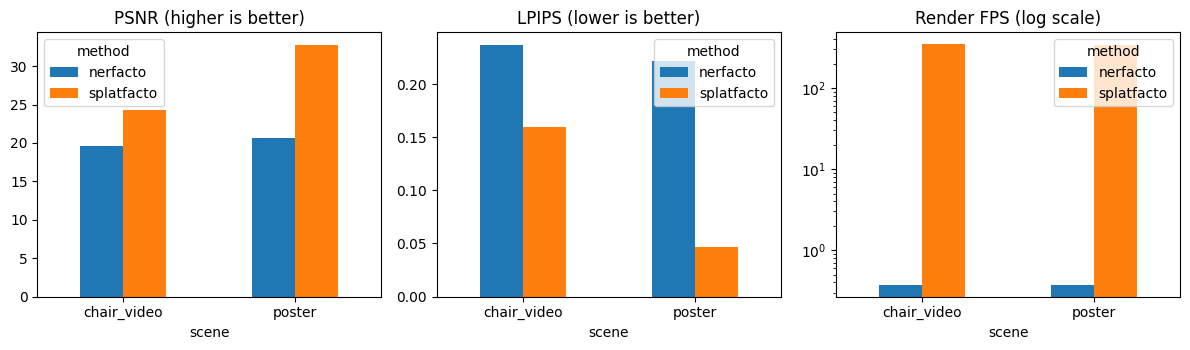

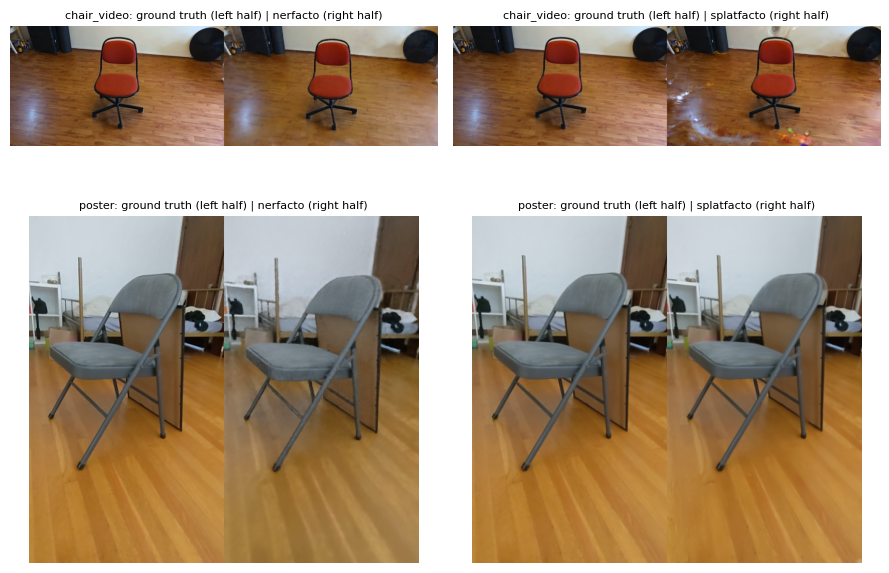

In [8]:
fig_dir = RESULTS / "figures"; fig_dir.mkdir(exist_ok=True)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
piv = lambda col: summ.pivot(index="scene", columns="method", values=col)
piv("psnr").plot.bar(ax=ax[0]); ax[0].set_title("PSNR (higher is better)"); ax[0].tick_params(axis="x", rotation=0)
piv("lpips").plot.bar(ax=ax[1]); ax[1].set_title("LPIPS (lower is better)"); ax[1].tick_params(axis="x", rotation=0)
piv("render_fps").plot.bar(ax=ax[2], logy=True); ax[2].set_title("Render FPS (log scale)"); ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(fig_dir / "quality_speed.png", dpi=150); plt.show()
# qualitative: ground truth | nerfacto | splatfacto for the first rendered view of each scene
fig, axes = plt.subplots(len(SCENES), 2, figsize=(9, 3.4 * len(SCENES))); axes = np.atleast_2d(axes)
for r, scene in enumerate(SCENES):
    for c, method in enumerate(["nerfacto", "splatfacto"]):
        imgs = sorted((RESULTS / "renders" / f"{scene}_{method}").glob("view*_img.png"))
        if imgs: axes[r][c].imshow(Image.open(imgs[0])); axes[r][c].set_title(f"{scene}: ground truth (left half) | {method} (right half)", fontsize=8)
        axes[r][c].axis("off")
plt.tight_layout(); plt.savefig(fig_dir / "renders.png", dpi=140); plt.show()

,scene,method,iterations,train_wall_s,train_energy_wh,psnr,ssim,lpips,render_fps_median
0,chair_video,nerfacto,2500,579.8,14.100,19.619,0.635,0.237,0.376
1,chair_video,splatfacto,15000,199.4,3.336,24.357,0.839,0.160,346.536
2,poster,nerfacto,2500,579.2,13.986,20.666,0.812,0.222,0.376
3,poster,splatfacto,15000,210.7,3.646,32.769,0.958,0.047,335.408


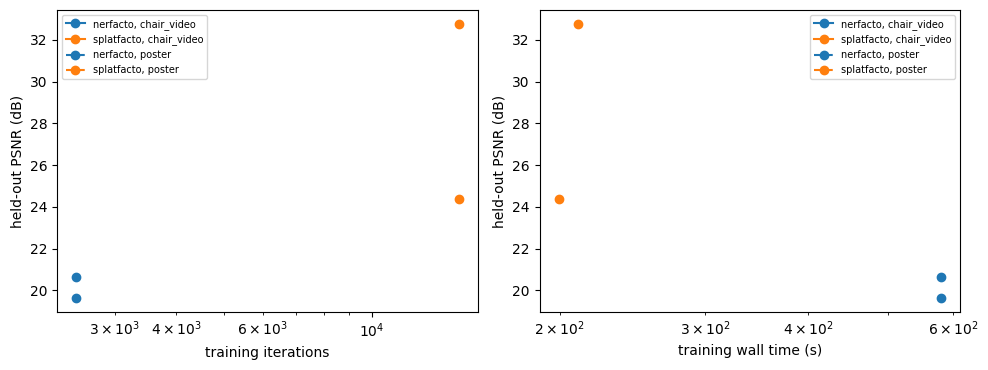

In [9]:
# 4b. quality against training effort: extra runs with other iteration counts, same scene, same held-out views
CURVE_RUNS = [("nerfacto", 5000), ("nerfacto", 10000), ("splatfacto", 1000), ("splatfacto", 3000), ("splatfacto", 7000)] if not QUICK else [("splatfacto", 50)]
if TRAIN_SEED: CURVE_RUNS = []      # replicate runs repeat only the two main runs per scene
curve = []
for scene in SCENES:
    for method, iters in CURVE_RUNS:
        exp = f"{scene}_{method}_{iters}"; out_json = RESULTS / f"eval_{exp}.json"
        cfg = OUT / exp / method / "run" / "config.yml"
        if not out_json.exists():
            if not list((OUT / exp / method / "run" / "nerfstudio_models").glob("step-*.ckpt")):
                sampler = GpuSampler(); sampler.start(); t0 = time.time()
                with (RESULTS / f"train_{exp}.log").open("w", encoding="utf-8") as lg: rc, text = sh(train_cmd(method, scene, iters, "run", exp), lg)
                wall = time.time() - t0; en = sampler.stop(); assert rc == 0, f"training failed for {exp}: see train_{exp}.log"
                with TRAIN_LOG.open("a") as f: f.write(json.dumps({"scene": scene, "method": method, "iterations": iters, "exit": rc, "wall_s": round(wall, 1), "tag": "curve", **en}) + "\n")
            rc, text = sh([PY, str(EVAL_WORKER), str(cfg), SCENES[scene]["eval_mode"], str(EVAL_VIEWS), str(out_json), str(RESULTS / "renders" / exp)])
            assert rc == 0 and out_json.exists(), f"evaluation failed for {exp}:\n{text[-1500:]}"
        d = json.loads(out_json.read_text()); r = pd.DataFrame(d["rows"]); logs = [json.loads(l) for l in TRAIN_LOG.read_text().splitlines()]
        wall = [x["wall_s"] for x in logs if x["scene"] == scene and x["method"] == method and x["iterations"] == iters and x.get("exit") == 0][-1]
        energy = [x["energy_wh"] for x in logs if x["scene"] == scene and x["method"] == method and x["iterations"] == iters and x.get("exit") == 0][-1]
        curve.append({"scene": scene, "method": method, "iterations": iters, "train_wall_s": wall, "train_energy_wh": energy, "psnr": r.psnr.mean(), "ssim": r.ssim.mean(), "lpips": r.lpips.mean(), "render_fps_median": r.fps.median()})
for (scene, method), d in EVAL_JSON.items():          # the two main runs
    t = tl.loc[(scene, method)]; r = pd.DataFrame(d["rows"])
    curve.append({"scene": scene, "method": method, "iterations": int(t.iterations), "train_wall_s": t.wall_s, "train_energy_wh": t.energy_wh, "psnr": r.psnr.mean(), "ssim": r.ssim.mean(), "lpips": r.lpips.mean(), "render_fps_median": r.fps.median()})
curve = pd.DataFrame(curve).drop_duplicates(["scene", "method", "iterations"], keep="last").sort_values(["scene", "method", "iterations"]).round(3); curve.to_csv(RESULTS / "quality_vs_effort.csv", index=False); display(curve)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for scene, ls in zip(curve.scene.unique(), ("-", "--", ":")):
    for method, c in (("nerfacto", "tab:blue"), ("splatfacto", "tab:orange")):
        g = curve[(curve.scene == scene) & (curve.method == method)].sort_values("iterations")
        ax[0].plot(g.iterations, g.psnr, "o" + ls, c=c, label=f"{method}, {scene}"); ax[1].plot(g.train_wall_s, g.psnr, "o" + ls, c=c, label=f"{method}, {scene}")
ax[0].set_xscale("log"); ax[0].set_xlabel("training iterations"); ax[1].set_xscale("log"); ax[1].set_xlabel("training wall time (s)")
for a in ax: a.set_ylabel("held-out PSNR (dB)"); a.legend(fontsize=7)
plt.tight_layout(); (RESULTS / "figures").mkdir(exist_ok=True); plt.savefig(RESULTS / "figures" / "quality_vs_effort.png", dpi=150); plt.show()

## 5. Data provenance and governance notes
- **chair:** from the NeRF-synthetic dataset (Blender models by several authors under CC-BY style licences, redistributed in the original NeRF release). Synthetic, no personal data.
- **poster:** nerfstudio sample capture of a poster; the capture shows no people. Real product captures in a shop would need consent checks for people, brands and locations that appear in the background.
- **Software:** nerfstudio and gsplat are Apache 2.0 licensed. The original 3D Gaussian Splatting research code has a separate non-commercial licence, which is why this project uses the gsplat reimplementation.

## 6. Notes for the report
Interpretation, limits and recommendations are written after the full run. Known limits: one training run per method and scene (no seed variation); iteration budgets were not tuned to convergence for either method (see the curve in Section 4b); nerfacto uses a pure-PyTorch hash grid and is therefore slower than a tiny-cuda-nn build; chair eval views are a 20-view subset of the validation split; the poster scene is small (100 low-resolution frames, 10 percent held out and taken from the same handheld sweep, so held-out views lie close to training views and PSNR measures interpolation rather than far novel views); PSNR from the scenes is not directly comparable with published full-resolution numbers; energy is GPU-only.